# 02 · Predicción de denuncias: ingenuo, perceptrón y MLP (Flavia)

Predice cuántas denuncias de robo y hurto tendrá cada distrito de Lima **el mes siguiente**. Se comparan tres modelos (hoja de ruta, sección 3.1):

1. **Ingenuo:** «igual que este mes».
2. **Perceptrón:** una neurona, con pesos ajustados con descenso del gradiente programado por nosotros (con curva de pérdida).
3. **MLP:** 1 o 2 capas ocultas de 8 a 32 neuronas con ReLU, entrenada con backpropagation programada por nosotros.

Entradas del modelo: denuncias del distrito en los meses t, t−1, t−2 y t−11; mes del año; marca de 2020 (cuarentena); área del distrito (OSM).
División: entrenamiento 2018–2024, validación 2025, prueba enero–julio 2026 (nunca al azar). Métricas: MAE, RMSE y MAPE.

Entradas: `data/processed/lima_robo_hurto_mensual.csv` (Miguel) y `data/processed/areas_distritos.csv` (Hugo).
Salida: `data/processed/prediccion_distritos.csv` (`UBIGEO`, `D_ESPERADAS`), que usa `04_ga`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAIZ = Path("..")                      # este notebook se ejecuta desde notebooks/
PROCESADOS = RAIZ / "data" / "processed"
FIGURAS = RAIZ / "outputs" / "figuras"

# Parámetros del MLP (los valores que se prueban están dentro de lo que pide la hoja de ruta)
ARQUITECTURAS = [[8], [16], [32], [8, 8], [16, 16], [32, 32]]   # 1–2 capas ocultas de 8–32 neuronas
TASA_MLP, EPOCAS_MLP, SEMILLA = 0.05, 3000, 0
ITERACIONES_PERCEPTRON = 20000

## 1. Datos
Una fila por distrito y mes (43 distritos × 103 meses, de enero 2018 a julio 2026). `TOTAL` es robo + hurto. El UBIGEO se lee siempre como texto.

In [2]:
datos = pd.read_csv(PROCESADOS / "lima_robo_hurto_mensual.csv", dtype={"UBIGEO": str}, parse_dates=["FECHA"])
areas = pd.read_csv(PROCESADOS / "areas_distritos.csv", dtype={"UBIGEO": str})[["UBIGEO", "AREA_KM2"]]
datos = datos.sort_values(["UBIGEO", "FECHA"]).reset_index(drop=True)

assert datos["UBIGEO"].nunique() == 43 and datos["FECHA"].nunique() == 103 and len(datos) == 43 * 103
assert areas["UBIGEO"].nunique() == 43 and areas["AREA_KM2"].gt(0).all()
# cada distrito tiene todos los meses seguidos: desplazar filas equivale a desplazar meses
assert (datos.groupby("UBIGEO")["FECHA"].diff().dropna().dt.days.between(28, 31)).all()
print("Filas:", len(datos), "| Distritos:", datos["UBIGEO"].nunique(), "| Meses:", datos["FECHA"].nunique())
datos.groupby("CONJUNTO")["FECHA"].agg(["min", "max", "nunique"])

Filas: 4429 | Distritos: 43 | Meses: 103


,min,max,nunique
CONJUNTO,,,
entrenamiento,2018-01-01,2024-12-01,84
prueba,2026-01-01,2026-07-01,7
validacion,2025-01-01,2025-12-01,12


## 2. Entradas y salida de cada fila
Cada fila del modelo representa **un mes que se quiere predecir** (el mes siguiente, `t+1`). Sus entradas salen de meses anteriores del mismo distrito:

| Entrada | Qué es |
|---|---|
| `D_t`, `D_t1`, `D_t2` | denuncias del mes anterior, de hace 2 y de hace 3 meses (t, t−1, t−2) |
| `D_t11` | denuncias del mismo mes del año anterior (t−11 es el mes `t+1` menos 12 meses) |
| `MES_SIN`, `MES_COS` | mes del año que se predice, escrito como seno y coseno para que diciembre y enero queden juntos |
| `CUARENTENA_2020` | 1 si el mes que se predice es de 2020 |
| `AREA_KM2` | área del distrito (OSM) |

La salida es `TOTAL` del mes `t+1`. Como la fila es el mes a predecir, su conjunto (entrenamiento, validación o prueba) es el que ya trae `CONJUNTO`.

In [3]:
g = datos.groupby("UBIGEO")["TOTAL"]
datos["D_t"], datos["D_t1"], datos["D_t2"], datos["D_t11"] = g.shift(1), g.shift(2), g.shift(3), g.shift(12)
datos["MES_SIN"] = np.sin(2 * np.pi * datos["MES"] / 12)
datos["MES_COS"] = np.cos(2 * np.pi * datos["MES"] / 12)
datos = datos.merge(areas, on="UBIGEO", how="left")

COLUMNAS = ["D_t", "D_t1", "D_t2", "D_t11", "MES_SIN", "MES_COS", "CUARENTENA_2020", "AREA_KM2"]
filas = datos.dropna(subset=["D_t", "D_t1", "D_t2", "D_t11"]).reset_index(drop=True)   # faltan los primeros 12 meses de cada distrito

# Comprobación a mano: las entradas de una fila son realmente los meses anteriores
ej = filas.iloc[-1]
serie = datos[datos["UBIGEO"] == ej["UBIGEO"]].set_index("FECHA")["TOTAL"]
f = ej["FECHA"]
assert (ej["D_t"], ej["D_t1"], ej["D_t2"], ej["D_t11"]) == tuple(serie[f - pd.DateOffset(months=k)] for k in (1, 2, 3, 12))
print("Filas del modelo:", len(filas)); filas.groupby("CONJUNTO").size()

Filas del modelo: 3913


CONJUNTO
entrenamiento    3096
prueba            301
validacion        516
dtype: int64

## 3. División temporal
Entrenamiento: meses a predecir de enero 2019 a diciembre 2024. Validación: 2025. Prueba: enero–julio 2026. **Nunca al azar:** una división aleatoria usaría datos futuros para predecir el pasado.
La validación sirve para elegir la arquitectura del MLP; la prueba se mira una sola vez, al final.

Las entradas se estandarizan (restar la media y dividir entre la desviación) **con los valores de entrenamiento**, y la salida se divide entre su desviación de entrenamiento. Así el descenso del gradiente no queda dominado por las variables con números más grandes.

In [4]:
entrenamiento = filas[filas["CONJUNTO"] == "entrenamiento"]
validacion = filas[filas["CONJUNTO"] == "validacion"]
prueba = filas[filas["CONJUNTO"] == "prueba"]
assert len(entrenamiento) == 72 * 43 and len(validacion) == 12 * 43 and len(prueba) == 7 * 43
assert entrenamiento["FECHA"].max() < validacion["FECHA"].min() and validacion["FECHA"].max() < prueba["FECHA"].min()

media, desv = entrenamiento[COLUMNAS].mean(), entrenamiento[COLUMNAS].std(ddof=0)
ESCALA_Y = entrenamiento["TOTAL"].std(ddof=0)
estandarizar = lambda tabla: ((tabla[COLUMNAS] - media) / desv).values

X_ent, X_val, X_pru = estandarizar(entrenamiento), estandarizar(validacion), estandarizar(prueba)
y_ent = entrenamiento["TOTAL"].values / ESCALA_Y
y_val, y_pru = validacion["TOTAL"].values, prueba["TOTAL"].values
print("Filas entrenamiento / validación / prueba:", len(entrenamiento), len(validacion), len(prueba))

Filas entrenamiento / validación / prueba: 3096 516 301


## 4. Métricas
* **MAE:** promedio del error en denuncias.
* **RMSE:** raíz del error cuadrático medio; castiga más los errores grandes.
* **MAPE:** promedio del error en porcentaje del valor real. No se puede calcular cuando el valor real es 0, así que esos casos se dejan fuera (se cuenta cuántos son).

In [5]:
def metricas(real, pred):
    error = real - pred
    con_valor = real > 0                      # el MAPE divide entre el valor real
    return {"MAE": np.mean(np.abs(error)),
            "RMSE": np.sqrt(np.mean(error ** 2)),
            "MAPE (%)": np.mean(np.abs(error[con_valor]) / real[con_valor]) * 100}

print("Meses con valor real 0 (fuera del MAPE): validación", int((y_val == 0).sum()), "| prueba", int((y_pru == 0).sum()))

Meses con valor real 0 (fuera del MAPE): validación 9 | prueba 4


## 5. Modelo 1: ingenuo
La predicción del mes siguiente es el valor de este mes (`D_t`). No aprende nada: es la referencia que hay que superar.

In [6]:
pred_ingenuo_val, pred_ingenuo_pru = validacion["D_t"].values, prueba["D_t"].values
pd.DataFrame({"Validación": metricas(y_val, pred_ingenuo_val), "Prueba": metricas(y_pru, pred_ingenuo_pru)}).round(2)

,Validación,Prueba
MAE,24.34,24.82
RMSE,38.75,38.08
MAPE (%),21.19,23.63


## 6. Modelo 2: perceptrón (una neurona, descenso del gradiente programado por nosotros)
Una sola neurona con salida lineal: `ŷ = w·x + b`. La pérdida es el error cuadrático medio y el descenso del gradiente actualiza los pesos en sentido contrario al gradiente: `w ← w − paso · ∂pérdida/∂w`.
El paso se fija en `1/L`, con `L` la constante de Lipschitz del gradiente (el mayor valor propio de `2/n · XᵀX`): con ese paso la pérdida baja en cada iteración.

Diferencia máxima con mínimos cuadrados (en denuncias): 1.82e-12


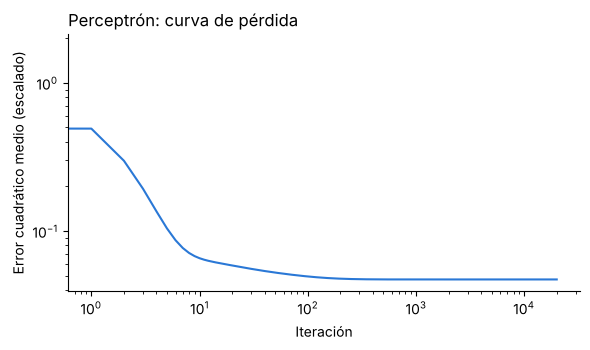

,Validación,Prueba
MAE,25.10,24.96
RMSE,38.27,38.37
MAPE (%),42.87,31.47


In [7]:
def entrenar_perceptron(X, y, iteraciones):
    n = len(y)
    Xb = np.c_[X, np.ones(n)]                              # la última columna es el sesgo b
    paso = 1 / (2 / n * np.linalg.eigvalsh(Xb.T @ Xb).max())
    w = np.zeros(Xb.shape[1])
    perdidas = []
    for _ in range(iteraciones):
        error = Xb @ w - y
        perdidas.append(np.mean(error ** 2))
        w = w - paso * (2 / n * Xb.T @ error)              # paso contra el gradiente
    return w, np.array(perdidas)

predecir_perceptron = lambda w, X: (np.c_[X, np.ones(len(X))] @ w) * ESCALA_Y

w_perc, perdidas_perc = entrenar_perceptron(X_ent, y_ent, ITERACIONES_PERCEPTRON)

# Comprobación: el descenso llega a la misma solución que mínimos cuadrados exactos
w_exacto = np.linalg.lstsq(np.c_[X_ent, np.ones(len(y_ent))], y_ent, rcond=None)[0]
dif = np.max(np.abs(predecir_perceptron(w_perc, X_val) - predecir_perceptron(w_exacto, X_val)))
print(f"Diferencia máxima con mínimos cuadrados (en denuncias): {dif:.2e}")
assert dif < 0.01
assert np.all(np.diff(perdidas_perc) <= 1e-12), "la pérdida debe bajar en cada iteración"

fig, eje = plt.subplots(figsize=(6, 3.6))
eje.plot(perdidas_perc, color="#2a78d6")
eje.set_yscale("log"); eje.set_xscale("log")
eje.set_xlabel("Iteración"); eje.set_ylabel("Error cuadrático medio (escalado)")
eje.set_title("Perceptrón: curva de pérdida", loc="left")
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIGURAS / "prediccion_perceptron_perdida.png", dpi=150); plt.show()

pred_perc_val, pred_perc_pru = predecir_perceptron(w_perc, X_val), predecir_perceptron(w_perc, X_pru)
pd.DataFrame({"Validación": metricas(y_val, pred_perc_val), "Prueba": metricas(y_pru, pred_perc_pru)}).round(2)

## 7. Modelo 3: MLP con backpropagation programada por nosotros
Red con 1 o 2 capas ocultas con ReLU y una neurona de salida lineal. Cada capa calcula `a = ReLU(a_anterior · W + b)`; la pérdida es el error cuadrático medio.
**Backpropagation:** se calcula el error de la salida y se propaga hacia atrás con la regla de la cadena; en cada capa, el error pasa por `Wᵀ` y por la derivada de ReLU (1 si la neurona estaba activa, 0 si no). Con esos gradientes los pesos bajan por descenso del gradiente.
Se prueban las arquitecturas permitidas (1–2 capas de 8, 16 o 32 neuronas) y **se elige la de menor MAE en validación**.

In [8]:
def entrenar_mlp(X, y, capas, paso, epocas, semilla):
    rng = np.random.default_rng(semilla)
    tam = [X.shape[1]] + capas + [1]
    W = [rng.normal(0, np.sqrt(2 / tam[i]), (tam[i], tam[i + 1])) for i in range(len(tam) - 1)]   # inicialización He (para ReLU)
    b = [np.zeros(tam[i + 1]) for i in range(len(tam) - 1)]
    n, perdidas = len(y), []
    for _ in range(epocas):
        # --- hacia adelante ---
        a, z = [X], []
        for i in range(len(W)):
            z.append(a[-1] @ W[i] + b[i])
            a.append(np.maximum(z[-1], 0) if i < len(W) - 1 else z[-1])      # ReLU en las ocultas, lineal en la salida
        error = a[-1][:, 0] - y
        perdidas.append(np.mean(error ** 2))
        # --- hacia atrás (backpropagation) ---
        delta = (2 / n * error)[:, None]                                     # derivada de la pérdida respecto a la salida
        for i in range(len(W) - 1, -1, -1):
            grad_W, grad_b = a[i].T @ delta, delta.sum(axis=0)
            if i > 0:
                delta = (delta @ W[i].T) * (z[i - 1] > 0)                    # pasa por Wᵀ y por la derivada de ReLU
            W[i] = W[i] - paso * grad_W
            b[i] = b[i] - paso * grad_b
    return W, b, np.array(perdidas)

def predecir_mlp(W, b, X):
    a = X
    for i in range(len(W)):
        a = a @ W[i] + b[i]
        if i < len(W) - 1:
            a = np.maximum(a, 0)
    return a[:, 0] * ESCALA_Y

resultados, modelos = [], {}
for capas in ARQUITECTURAS:
    W, b, perdidas = entrenar_mlp(X_ent, y_ent, capas, TASA_MLP, EPOCAS_MLP, SEMILLA)
    modelos[str(capas)] = (W, b, perdidas)
    m = metricas(y_val, predecir_mlp(W, b, X_val))
    resultados.append({"capas ocultas": str(capas), "pérdida de entrenamiento": perdidas[-1], **{f"{k} (val.)": v for k, v in m.items()}})
tabla_mlp = pd.DataFrame(resultados).set_index("capas ocultas")
elegida = tabla_mlp["MAE (val.)"].idxmin()
print("Arquitectura elegida por menor MAE en validación:", elegida)
tabla_mlp.round(3)

Arquitectura elegida por menor MAE en validación: [8]


,pérdida de entrenamiento,MAE (val.),RMSE (val.),MAPE (%) (val.)
capas ocultas,,,,
[8],0.044,25.967,39.655,33.680
[16],0.042,26.731,42.090,40.497
[32],0.041,26.028,40.093,47.672
"[8, 8]",0.040,27.805,41.823,49.730
"[16, 16]",0.042,31.304,47.095,54.314
"[32, 32]",0.035,27.284,41.963,38.410


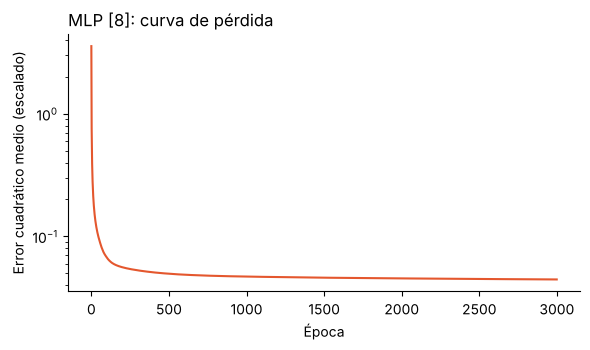

In [9]:
W_mlp, b_mlp, perdidas_mlp = modelos[elegida]
fig, eje = plt.subplots(figsize=(6, 3.6))
eje.plot(perdidas_mlp, color="#e4572e")
eje.set_yscale("log")
eje.set_xlabel("Época"); eje.set_ylabel("Error cuadrático medio (escalado)")
eje.set_title(f"MLP {elegida}: curva de pérdida", loc="left")
eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIGURAS / "prediccion_mlp_perdida.png", dpi=150); plt.show()

pred_mlp_val, pred_mlp_pru = predecir_mlp(W_mlp, b_mlp, X_val), predecir_mlp(W_mlp, b_mlp, X_pru)

## 8. Comparación de los tres modelos

In [10]:
comparacion = pd.concat({
    "Ingenuo": pd.DataFrame({"Validación": metricas(y_val, pred_ingenuo_val), "Prueba": metricas(y_pru, pred_ingenuo_pru)}),
    "Perceptrón": pd.DataFrame({"Validación": metricas(y_val, pred_perc_val), "Prueba": metricas(y_pru, pred_perc_pru)}),
    f"MLP {elegida}": pd.DataFrame({"Validación": metricas(y_val, pred_mlp_val), "Prueba": metricas(y_pru, pred_mlp_pru)}),
}).T.round(2)
comparacion

Ingenuo                 Perceptrón                 MLP [8]         \
               MAE   RMSE MAPE (%)        MAE   RMSE MAPE (%)     MAE   RMSE   
Validación   24.34  38.75    21.19      25.10  38.27    42.87   25.97  39.65   
Prueba       24.82  38.08    23.63      24.96  38.37    31.47   27.36  41.28   

                     
           MAPE (%)  
Validación    33.68  
Prueba        40.62

## 9. Salida: denuncias esperadas del mes siguiente (`D_ESPERADAS`)
Con los datos hasta julio 2026, la salida es la predicción para **agosto 2026** de cada distrito, con la MLP elegida (la hoja de ruta indica que `Dᵢ` viene de la MLP). Las entradas son julio, junio y mayo de 2026 y agosto de 2025.

In [11]:
tabla = datos.pivot(index="UBIGEO", columns="FECHA", values="TOTAL")
ultimo = tabla.columns.max()
objetivo = ultimo + pd.DateOffset(months=1)
assert ultimo == pd.Timestamp("2026-07-01") and objetivo == pd.Timestamp("2026-08-01")

entrada = pd.DataFrame({
    "D_t": tabla[ultimo], "D_t1": tabla[ultimo - pd.DateOffset(months=1)],
    "D_t2": tabla[ultimo - pd.DateOffset(months=2)], "D_t11": tabla[objetivo - pd.DateOffset(years=1)],
}).reset_index()
entrada["MES_SIN"], entrada["MES_COS"] = np.sin(2 * np.pi * objetivo.month / 12), np.cos(2 * np.pi * objetivo.month / 12)
entrada["CUARENTENA_2020"] = int(objetivo.year == 2020)
entrada = entrada.merge(areas, on="UBIGEO", how="left")

prediccion = predecir_mlp(W_mlp, b_mlp, estandarizar(entrada))
salida = pd.DataFrame({"UBIGEO": entrada["UBIGEO"], "D_ESPERADAS": np.round(np.maximum(prediccion, 0), 2)})   # un conteo no puede ser negativo

assert len(salida) == 43 and salida["UBIGEO"].is_unique and salida["D_ESPERADAS"].notna().all() and (salida["D_ESPERADAS"] >= 0).all()
salida.to_csv(PROCESADOS / "prediccion_distritos.csv", index=False)
print("Guardado prediccion_distritos.csv", salida.shape, "| total esperado agosto 2026:", round(salida["D_ESPERADAS"].sum()),
      "| total real julio 2026:", int(tabla[ultimo].sum()))
salida.merge(entrada[["UBIGEO", "D_t"]], on="UBIGEO").rename(columns={"D_t": "REAL_JULIO_2026"}).head(10)

Guardado prediccion_distritos.csv (43, 2) | total esperado agosto 2026: 8385 | total real julio 2026: 7862


,UBIGEO,D_ESPERADAS,REAL_JULIO_2026
0,150101,895.45,840
1,150102,23.04,25
2,150103,377.28,348
3,150104,72.87,78
4,150105,162.10,169
5,150106,172.06,164
6,150107,46.17,51
7,150108,277.98,261
8,150109,24.23,15
9,150110,292.12,262


## 10. Lectura y limitaciones
* **Resultado:** en validación y en prueba, el MLP (1 capa de 8 neuronas) **no le gana** al ingenuo ni al perceptrón en MAE, RMSE ni MAPE (excepto un RMSE de validación del perceptrón algo menor que el ingenuo, 38,27 frente a 38,75, que no se repite en prueba). El criterio de la hoja de ruta («la MLP debe ganarle al ingenuo y al perceptrón») **no se cumple** con estas entradas.
* **Por qué puede pasar (no se probó aquí):** de un mes al siguiente el número de denuncias de un distrito cambia poco, así que «igual que este mes» ya es una referencia muy difícil de superar; además, los modelos aprenden el patrón de 2019–2024 y se evalúan en 2025–2026.
* **MAPE:** es mucho mayor en el perceptrón y la MLP que en el ingenuo porque los errores relativos pesan más en los distritos con pocas denuncias (y el MAPE deja fuera los meses con valor real 0).
* **Elección de la MLP:** la arquitectura se eligió con una sola semilla (`SEMILLA = 0`); otra semilla puede dar valores algo distintos.
* **Salida:** `D_ESPERADAS` se calcula con la MLP elegida, como indica la hoja de ruta, aunque en validación y prueba el ingenuo tuvo menor error. Está entrenada solo con 2018–2024.
* Los datos son denuncias, no delitos: miden dónde la gente denuncia.